Lab 3: Ticket Escalation Prediction

Explores the ticket data and trains a few classification models to predict whether. It also checks how changing the decision threshold affects the results. The original dataset was provided as a CSV table.

1. Libraries

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
    classification_report, RocCurveDisplay
)

2. Read and check the data

In [2]:
df = pd.read_csv("classification_escalation.csv")

print("Rows and columns:", df.shape)
display(df.head())

print("\nMissing values:")
print(df.isnull().sum())

print("\nTarget counts:")
print(df["escalated"].value_counts())

Rows and columns: (900, 6)


,complexity_score,team_experience_years,priority,channel,customer_tenure_months,escalated
0,9,7.7,low,web,21.6,0
1,2,6.1,high,web,21.8,0
2,1,2.5,medium,phone,28.8,0
3,7,5.3,low,email,52.5,0
4,4,7.1,medium,email,14.7,0



Missing values:
complexity_score           0
team_experience_years     31
priority                  18
channel                    0
customer_tenure_months    22
escalated                  0
dtype: int64

Target counts:
escalated
0    714
1    186
Name: count, dtype: int64


The target is `escalated`. A value of 1 means the ticket was escalated, and 0 means it was not. Since fewer tickets may be escalated, I will look at more than accuracy when evaluating models.

3. Split the data and prepare features

In [12]:
X = df.drop("escalated", axis=1)
y = df["escalated"]

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)

X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_full, y_train_full, test_size=0.20,
    stratify=y_train_full, random_state=42
)

num_cols = ["complexity_score", "team_experience_years", "customer_tenure_months"]
cat_cols = ["priority", "channel"]

num_pipe = Pipeline([
    ("fill", SimpleImputer(strategy="median")),
    ("scale", StandardScaler())
])

cat_pipe = Pipeline([
    ("fill", SimpleImputer(strategy="most_frequent")),
    ("encode", OneHotEncoder(handle_unknown="ignore"))
])

prep = ColumnTransformer([
    ("numbers", num_pipe, num_cols),
    ("categories", cat_pipe, cat_cols)
])

The data is divided into training, validation, and test sets. The training set fits the models, the validation set helps compare models and choose a probability threshold, and the test set is kept for the final evaluation. Numeric missing values are filled with the median and scaled. Categorical missing values are filled with the most common category and encoded. Preprocessing is fitted inside each model pipeline to avoid data leakage.

4. Train and compare models

I compare a majority-class baseline with Logistic Regression, LDA, and k-NN. The validation set is used for this comparison; the test set remains untouched until the final evaluation.

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
LDA,0.785,0.444,0.143,0.216,0.772
k-NN,0.763,0.333,0.143,0.200,0.709
Logistic Regression,0.778,0.375,0.107,0.167,0.770
Baseline,0.793,0.000,0.000,0.000,0.500


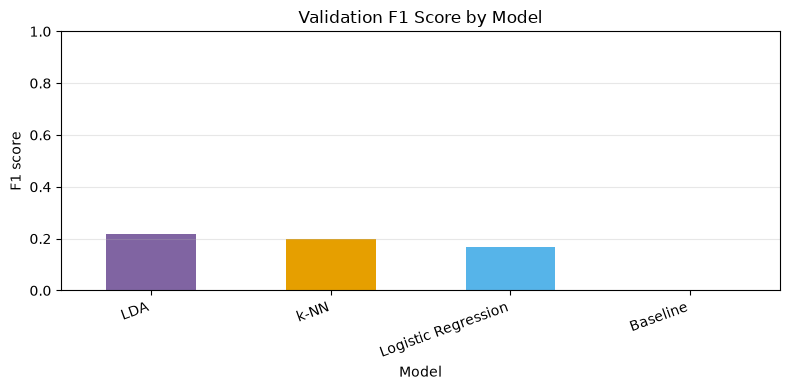

In [4]:
classifiers = {
    "Baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=1500),
    "LDA": LinearDiscriminantAnalysis(),
    "k-NN": KNeighborsClassifier(n_neighbors=15)
}

scores = []
fitted = {}

for name, clf in classifiers.items():
    pipe = Pipeline([
        ("prep", prep),
        ("model", clf)
    ])
    pipe.fit(X_train, y_train)
    fitted[name] = pipe

    y_hat = pipe.predict(X_valid)
    scores.append({
        "Model": name,
        "Accuracy": accuracy_score(y_valid, y_hat),
        "Precision": precision_score(y_valid, y_hat, zero_division=0),
        "Recall": recall_score(y_valid, y_hat, zero_division=0),
        "F1": f1_score(y_valid, y_hat, zero_division=0),
        "ROC-AUC": roc_auc_score(y_valid, pipe.predict_proba(X_valid)[:, 1])
    })

score_table = pd.DataFrame(scores).set_index("Model").sort_values("F1", ascending=False)
display(score_table.round(3))

score_table["F1"].plot(kind="bar", figsize=(8, 4), color=["#8064A2", "#E69F00", "#56B4E9", "#009E73"])
plt.title("Validation F1 Score by Model")
plt.xlabel("Model")
plt.ylabel("F1 score")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

5. Look at Logistic Regression

Inspect its validation confusion matrix, ROC curve, and classification report.

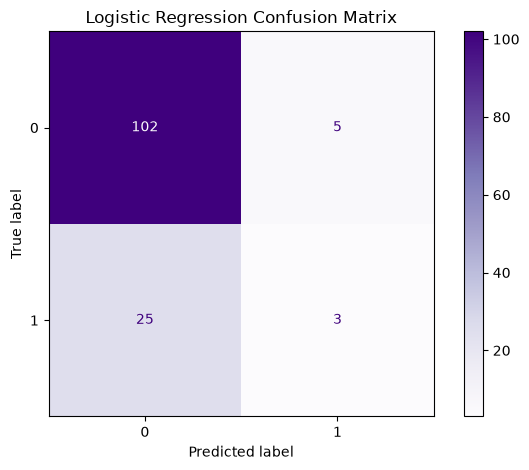

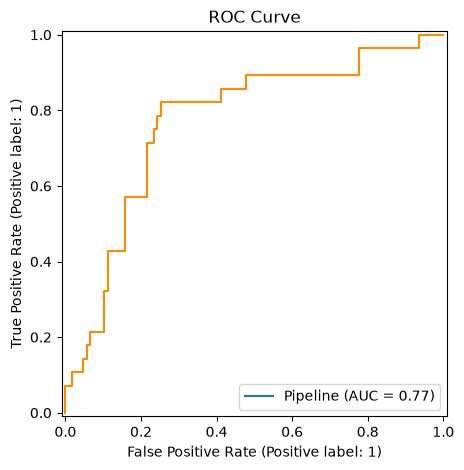

              precision    recall  f1-score   support

           0       0.80      0.95      0.87       107
           1       0.38      0.11      0.17        28

    accuracy                           0.78       135
   macro avg       0.59      0.53      0.52       135
weighted avg       0.71      0.78      0.73       135



In [5]:
lr = fitted["Logistic Regression"]
lr_pred = lr.predict(X_valid)

ConfusionMatrixDisplay.from_predictions(y_valid, lr_pred, cmap="Purples")
plt.title("Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.show()

RocCurveDisplay.from_estimator(lr, X_valid, y_valid)
plt.gca().get_lines()[0].set_color("darkorange")
plt.title("ROC Curve")
plt.tight_layout()
plt.show()

print(classification_report(y_valid, lr_pred, zero_division=0))

6. Test different probability thresholds

Instead of using the default 0.50, I try several thresholds on the validation set. I also calculate the illustrative cost `5 * FN + FP`, where missing an escalation (FN) is assumed to be five times as costly as a false alarm (FP).

In [6]:
prob = lr.predict_proba(X_valid)[:, 1]
thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]
rows = []

for t in thresholds:
    guess = (prob >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_valid, guess, labels=[0, 1]).ravel()

    rows.append({
        "Threshold": t,
        "Precision": precision_score(y_valid, guess, zero_division=0),
        "Recall": recall_score(y_valid, guess, zero_division=0),
        "F1": f1_score(y_valid, guess, zero_division=0),
        "FP": fp,
        "FN": fn,
        "Cost": 5 * fn + fp
    })

threshold_table = pd.DataFrame(rows)
display(threshold_table.round(3))

lowest_cost = threshold_table.loc[threshold_table["Cost"].idxmin()]
selected_threshold = float(lowest_cost["Threshold"])
print("Lowest validation cost threshold:", selected_threshold)
print("Validation cost:", lowest_cost["Cost"])

,Threshold,Precision,Recall,F1,FP,FN,Cost
0,0.2,0.365,0.821,0.505,40,5,65
1,0.3,0.421,0.571,0.485,22,12,82
2,0.4,0.478,0.393,0.431,12,17,97
3,0.5,0.375,0.107,0.167,5,25,130
4,0.6,0.667,0.071,0.129,1,26,131
5,0.7,1.000,0.036,0.069,0,27,135


Lowest validation cost threshold: 0.2
Validation cost: 65.0


Visualize threshold trade-offs

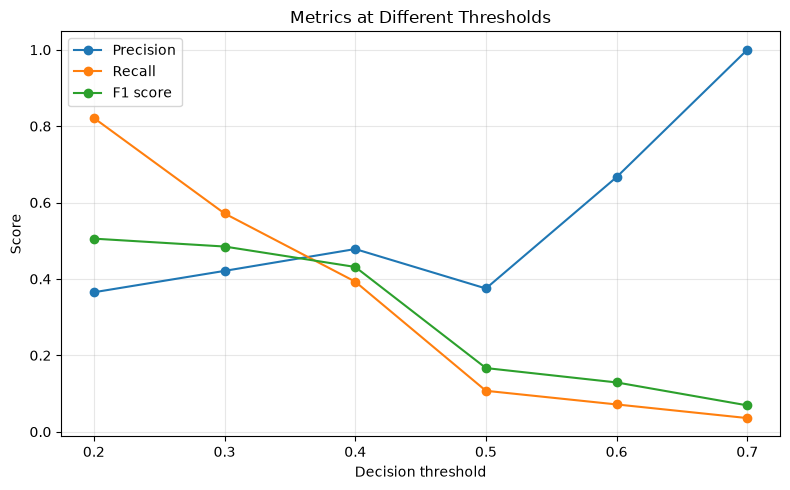

In [7]:
plt.figure(figsize=(8, 5))
plt.plot(threshold_table["Threshold"], threshold_table["Precision"], marker="o", color="tab:blue", label="Precision")
plt.plot(threshold_table["Threshold"], threshold_table["Recall"], marker="o", color="tab:orange", label="Recall")
plt.plot(threshold_table["Threshold"], threshold_table["F1"], marker="o", color="tab:green", label="F1 score")
plt.xlabel("Decision threshold")
plt.ylabel("Score")
plt.title("Metrics at Different Thresholds")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

A lower threshold usually increases recall because more tickets are predicted as escalated, but it can also lower precision and increase false alarms. The table helps compare this trade-off. The threshold is selected using validation data, not the test set, so the final test evaluation remains independent.

7. Calculate a threshold from the assumed costs

In [8]:
# Assume FP costs 1 and FN costs 5
cost_fp = 1
cost_fn = 5

cost_threshold = cost_fp / (cost_fp + cost_fn)
print("Cost-based threshold:", cost_threshold)

cost_pred = (prob >= cost_threshold).astype(int)
print("Validation confusion matrix:")
print(confusion_matrix(y_valid, cost_pred))
print("Validation classification report:")
print(classification_report(y_valid, cost_pred, zero_division=0))

Cost-based threshold: 0.16666666666666666
Validation confusion matrix:
[[60 47]
 [ 4 24]]
Validation classification report:
              precision    recall  f1-score   support

           0       0.94      0.56      0.70       107
           1       0.34      0.86      0.48        28

    accuracy                           0.62       135
   macro avg       0.64      0.71      0.59       135
weighted avg       0.81      0.62      0.66       135



If a ticket is escalated, the expected false-positive cost is `1 × (1-p)`. If it is not escalated, the expected false-negative cost is `5 × p`. We escalate when:

`1 - p < 5p`, which gives `p > 1/6`, or about 0.167.

This threshold comes from the assumed costs. Real costs and the team's ability to review flagged cases should be considered before using it.

8. Tune k-NN using cross-validation

Cross-validation selects the number of neighbors using only the training data. The selected model is then evaluated on the held-out test set.

In [9]:
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

knn_pipe = Pipeline([
    ("prep", prep),
    ("model", KNeighborsClassifier())
])

search = GridSearchCV(
    knn_pipe,
    param_grid={"model__n_neighbors": [5, 9, 15, 21, 31]},
    scoring="f1",
    cv=folds
)

search.fit(X_train_full, y_train_full)

print("Best k:", search.best_params_)
print("Best average CV F1:", round(search.best_score_, 3))

best_knn = search.best_estimator_
print("\nTest report for tuned k-NN:")
print(classification_report(y_test, best_knn.predict(X_test), zero_division=0))

Best k: {'model__n_neighbors': 5}
Best average CV F1: 0.243

Test report for tuned k-NN:
              precision    recall  f1-score   support

           0       0.81      0.96      0.88       179
           1       0.46      0.13      0.20        46

    accuracy                           0.79       225
   macro avg       0.64      0.55      0.54       225
weighted avg       0.74      0.79      0.74       225



Cross-validation tests different values of k on several training folds. The search chooses the value with the highest average F1 score using the training portion. The tuned model is then evaluated on the held-out test set.

9. Bayesian terms in this problem

- Prior: the proportion of tickets that are escalated before considering their features.
- Likelihood: how compatible the observed features are with an outcome class.
- Evidence: the overall probability of observing those features.
- Posterior: the updated probability of escalation after considering the features, written as `P(escalated | features)`.

These terms explain Bayesian reasoning. A Bayesian classifier is not trained in this notebook.

10. Final evaluation and conclusion

The validation set was used to compare models and select a threshold. The test set is used here for a final, independent evaluation of Logistic Regression at the selected threshold.

In [10]:
test_prob = lr.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= selected_threshold).astype(int)

print("Selected validation threshold:", selected_threshold)
print("Test confusion matrix:")
print(confusion_matrix(y_test, test_pred))
print("Test classification report:")
print(classification_report(y_test, test_pred, zero_division=0))
print("Test ROC-AUC:", round(roc_auc_score(y_test, test_prob), 3))

Selected validation threshold: 0.2
Test confusion matrix:
[[127  52]
 [ 11  35]]
Test classification report:
              precision    recall  f1-score   support

           0       0.92      0.71      0.80       179
           1       0.40      0.76      0.53        46

    accuracy                           0.72       225
   macro avg       0.66      0.74      0.66       225
weighted avg       0.81      0.72      0.75       225

Test ROC-AUC: 0.808


The experiment compares a majority-class baseline with Logistic Regression, LDA, and k-NN for ticket escalation prediction. Precision, recall, F1, and ROC-AUC provide a broader view than accuracy alone. The threshold analysis shows the trade-off between detecting more escalations and creating more false alarms. Threshold selection is performed on validation data, while the test set is reserved for final evaluation. The cost-based threshold is meaningful only under the stated cost assumptions. Results should be checked on representative data before any real-world use.